# Section 4 results

Every figure and table in Section 4 of the report comes from this notebook: neil-mac, final commit `94403ce`. Each point is the median of 5 reps; error bars and the q1/q3 columns show the interquartile range (IQR).

## Setup

In [1]:
import os
import pandas as pd, numpy as np, matplotlib.pyplot as plt

FINAL = "94403ce"   # code_version of your full post-fix E1–E7 run
os.makedirs("figures", exist_ok=True)

df = pd.read_csv("../results/timings.csv")
r = df[(df['machine_id'] == 'neil-mac') & (df['code_version'] == FINAL)].copy()
r['ns_per_op'] = r['total_ns'] / r['n_ops']
r['us_per_op'] = r['ns_per_op'] / 1000
r['cmp_per_op'] = r['comparisons'] / r['n_ops']

# sanity check: every experiment present
print(r.groupby('experiment').size())

def slope(x, y):
    """log-log slope: ~0 = O(1), ~1 = O(n), ~2 = O(n^2)"""
    return np.polyfit(np.log(x), np.log(y), 1)[0]

INDEXES = ['unsorted_list', 'sorted_list', 'hash_table', 'avl_tree', 'bplus_tree', 'ref_dict', 'ref_bisect']

def q1(x): return x.quantile(0.25)
def q3(x): return x.quantile(0.75)

def errbar(ax, x, med, lo, hi, label, fmt='o-'):
    """Median with asymmetric error bars from the 25th to the 75th percentile (IQR)."""
    ax.errorbar(x, med, yerr=[med - lo, hi - med], fmt=fmt, capsize=3, label=label)


experiment
E1_build_track_id       245
E2_point_track_id       490
E3_range_tempo          210
E4_prefix_track_name    175
E5_insert_order         840
E6_bplus_order          180
E7_duplicate_keys       455
example                 210
dtype: int64


## E1: build cost vs n

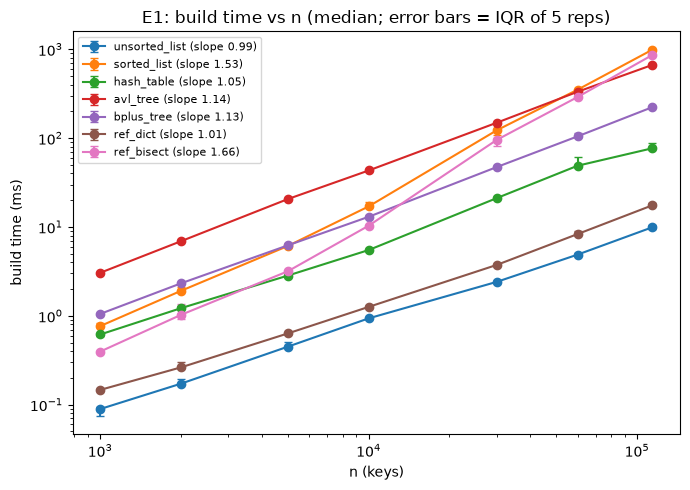

,build_ms,q1_ms,q3_ms,bytes_per_key
index_type,,,,
unsorted_list,9.9,9.5,10.5,65.0
ref_dict,17.5,17.5,18.5,92.0
hash_table,76.8,76.5,87.9,195.0
bplus_tree,223.0,222.4,228.1,80.0
avl_tree,666.2,646.2,669.7,115.0
ref_bisect,861.5,855.6,881.8,73.0
sorted_list,988.5,979.4,989.5,73.0


index_type,avl_tree,bplus_tree,hash_table,ref_bisect,ref_dict,sorted_list,unsorted_list
n_keys,,,,,,,
1000,7,6,4,3,2,5,1
2000,7,6,4,3,2,5,1
5000,7,6,3,4,2,5,1
10000,7,5,3,4,2,6,1
30000,7,4,3,5,2,6,1
60000,6,4,3,5,2,7,1
114000,5,4,3,6,2,7,1


In [2]:
e1 = r[r['experiment'].str.startswith('E1')]
m1 = e1.groupby(['index_type', 'n_keys']).agg(
    build_ms=('total_ns', lambda x: x.median() / 1e6),
    q1_ms=('total_ns', lambda x: x.quantile(0.25) / 1e6),
    q3_ms=('total_ns', lambda x: x.quantile(0.75) / 1e6),
    mem=('memory_bytes', 'median')).reset_index()

fig, ax = plt.subplots(figsize=(7, 5))
for idx in INDEXES:
    g = m1[m1['index_type'] == idx]
    errbar(ax, g['n_keys'], g['build_ms'], g['q1_ms'], g['q3_ms'], f"{idx} (slope {slope(g['n_keys'], g['build_ms']):.2f})")
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('n (keys)'); ax.set_ylabel('build time (ms)')
ax.set_title('E1: build time vs n (median; error bars = IQR of 5 reps)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('figures/e1_build.png', dpi=150); plt.show()

full = m1[m1['n_keys'] == m1['n_keys'].max()].set_index('index_type')
full['bytes_per_key'] = (full['mem'] / m1['n_keys'].max()).round(0)
display(full[['build_ms', 'q1_ms', 'q3_ms', 'bytes_per_key']].round(1).sort_values('build_ms'))

# crossovers: rank of each index (1 = fastest build) at every n
display(m1.pivot(index='n_keys', columns='index_type', values='build_ms').rank(axis=1).astype(int))

## E2: point lookups vs n

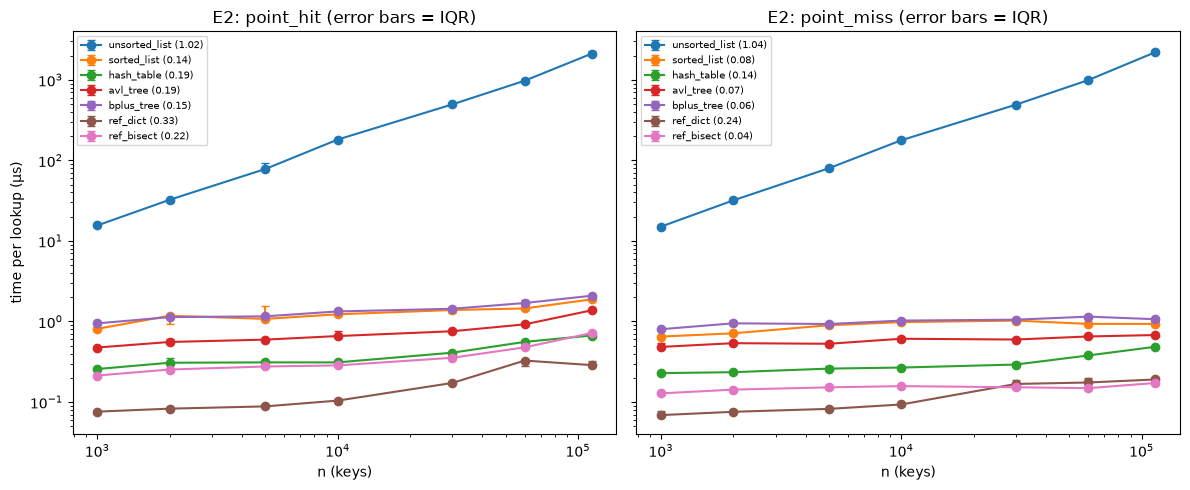

us_per_op                   q1                   q3             \
operation     point_hit point_miss point_hit point_miss point_hit point_miss   
index_type                                                                     
avl_tree           1.38       0.68      1.35       0.67      1.40       0.69   
bplus_tree         2.09       1.07      1.92       1.06      2.13       1.07   
hash_table         0.67       0.49      0.67       0.48      0.68       0.49   
ref_bisect         0.72       0.17      0.72       0.16      0.72       0.17   
ref_dict           0.29       0.19      0.29       0.19      0.33       0.19   
sorted_list        1.88       0.93      1.87       0.92      1.94       1.01   
unsorted_list   2112.13    2203.03   2092.62    2130.22   2311.68    2369.77   

              cmp_per_op             
operation      point_hit point_miss  
index_type                           
avl_tree           15.73      16.00  
bplus_tree         16.76      15.00  
hash_table          1.34       0.65  
ref_bisect           NaN        NaN  
ref_dict             NaN        NaN  
sorted_list        16.52      16.00  
unsorted_list  114000.00  114000.00

index_type,avl_tree,bplus_tree,hash_table,ref_bisect,ref_dict,sorted_list,unsorted_list
n_keys,,,,,,,
1000,4,6,3,2,1,5,7
2000,4,5,3,2,1,6,7
5000,4,6,3,2,1,5,7
10000,4,6,3,2,1,5,7
30000,4,6,3,2,1,5,7
60000,4,6,3,2,1,5,7
114000,4,6,2,3,1,5,7


In [3]:
e2 = r[r['experiment'].str.startswith('E2')]
m2 = e2.groupby(['index_type', 'operation', 'n_keys']).agg(
    us_per_op=('us_per_op', 'median'), q1=('us_per_op', q1), q3=('us_per_op', q3),
    cmp_per_op=('cmp_per_op', 'median')).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, op in zip(axes, ['point_hit', 'point_miss']):
    for idx in INDEXES:
        g = m2[(m2['index_type'] == idx) & (m2['operation'] == op)]
        errbar(ax, g['n_keys'], g['us_per_op'], g['q1'], g['q3'], f"{idx} ({slope(g['n_keys'], g['us_per_op']):.2f})")
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlabel('n (keys)'); ax.set_title(f'E2: {op} (error bars = IQR)'); ax.legend(fontsize=7)
axes[0].set_ylabel('time per lookup (µs)')
plt.tight_layout(); plt.savefig('figures/e2_lookup.png', dpi=150); plt.show()

at_full = m2[m2['n_keys'] == m2['n_keys'].max()]
display(at_full.pivot(index='index_type', columns='operation', values=['us_per_op', 'q1', 'q3', 'cmp_per_op']).round(2))
display(m2[m2['operation'] == 'point_hit'].pivot(index='n_keys', columns='index_type', values='us_per_op').rank(axis=1).astype(int))

## E3: range cost vs selectivity

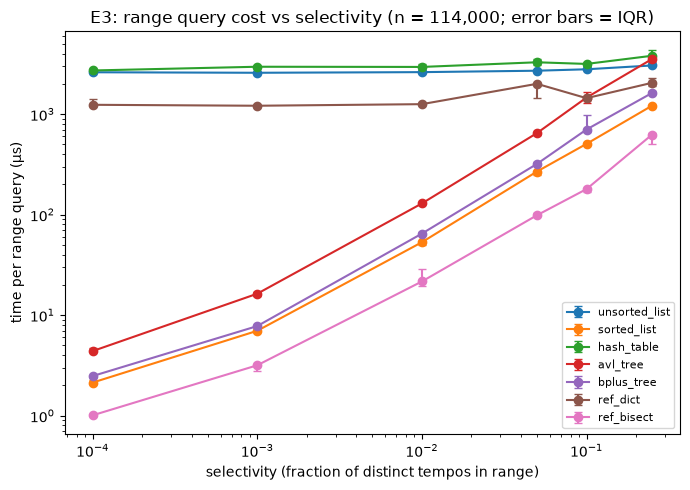

index_type,avl_tree,bplus_tree,hash_table,ref_bisect,ref_dict,sorted_list,unsorted_list
operation_param,,,,,,,
0.0001,4.4,2.5,2719.7,1.0,1239.1,2.1,2611.4
0.0010,16.3,7.8,2962.8,3.2,1212.4,7.0,2580.5
0.0100,129.3,64.8,2949.5,21.6,1257.1,53.2,2618.3
0.0500,648.0,319.8,3282.1,98.7,2003.6,268.5,2705.0
0.1000,1461.7,703.3,3160.1,179.6,1442.4,506.3,2795.2
0.2500,3535.8,1625.1,3809.4,625.5,2049.7,1214.5,3050.6


q1                                            \
index_type      avl_tree bplus_tree hash_table ref_bisect ref_dict   
operation_param                                                      
0.0001               4.4        2.4     2638.0        1.0   1218.6   
0.0010              15.6        7.8     2643.4        2.8   1168.3   
0.0100             126.9       64.0     2658.1       19.5   1247.3   
0.0500             621.6      309.4     3063.8       98.4   1446.3   
0.1000            1287.8      663.2     3028.6      167.5   1415.9   
0.2500            3307.6     1581.7     3622.2      501.3   1921.5   

                                                q3                        \
index_type      sorted_list unsorted_list avl_tree bplus_tree hash_table   
operation_param                                                            
0.0001                  2.1        2609.3      4.7        2.5     2789.7   
0.0010                  7.0        2562.0     16.9        7.8     3022.9   
0.0100                 50.3        2596.7    129.7       67.3     3120.5   
0.0500                248.3        2662.7    652.1      336.9     3510.4   
0.1000                504.3        2785.8   1668.3      991.8     3192.8   
0.2500               1213.7        3049.5   3564.0     1701.1     4384.0   

                                                               
index_type      ref_bisect ref_dict sorted_list unsorted_list  
operation_param                                                
0.0001                 1.0   1426.1         2.3        2612.7  
0.0010                 3.2   1221.8         7.9        2594.9  
0.0100                28.5   1278.2        53.4        2652.5  
0.0500               103.2   2010.9       271.4        2721.3  
0.1000               180.8   1452.2       515.8        2816.1  
0.2500               655.0   2303.5      1223.7        3053.9

index_type,avl_tree,bplus_tree,hash_table,ref_bisect,ref_dict,sorted_list,unsorted_list
operation_param,,,,,,,
0.0001,19.0,22.0,45653.0,NaN,NaN,22.0,114000.0
0.0010,60.0,63.0,45653.0,NaN,NaN,63.0,114000.0
0.0100,471.0,474.0,45653.0,NaN,NaN,474.0,114000.0
0.0500,2296.0,2300.0,45653.0,NaN,NaN,2300.0,114000.0
0.1000,4578.0,4582.0,45653.0,NaN,NaN,4582.0,114000.0
0.2500,11426.0,11430.0,45653.0,NaN,NaN,11430.0,114000.0


In [4]:
e3 = r[r['experiment'].str.startswith('E3')]
m3 = e3.groupby(['index_type', 'operation_param']).agg(
    us_per_op=('us_per_op', 'median'), q1=('us_per_op', q1), q3=('us_per_op', q3),
    cmp_per_op=('cmp_per_op', 'median')).reset_index()

fig, ax = plt.subplots(figsize=(7, 5))
for idx in INDEXES:
    g = m3[m3['index_type'] == idx]
    errbar(ax, g['operation_param'], g['us_per_op'], g['q1'], g['q3'], idx)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('selectivity (fraction of distinct tempos in range)'); ax.set_ylabel('time per range query (µs)')
ax.set_title('E3: range query cost vs selectivity (n = 114,000; error bars = IQR)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('figures/e3_range.png', dpi=150); plt.show()

display(m3.pivot(index='operation_param', columns='index_type', values='us_per_op').round(1))
display(m3.pivot(index='operation_param', columns='index_type', values=['q1', 'q3']).round(1))
display(m3.pivot(index='operation_param', columns='index_type', values='cmp_per_op').round(0))

## E4: prefix cost vs prefix length

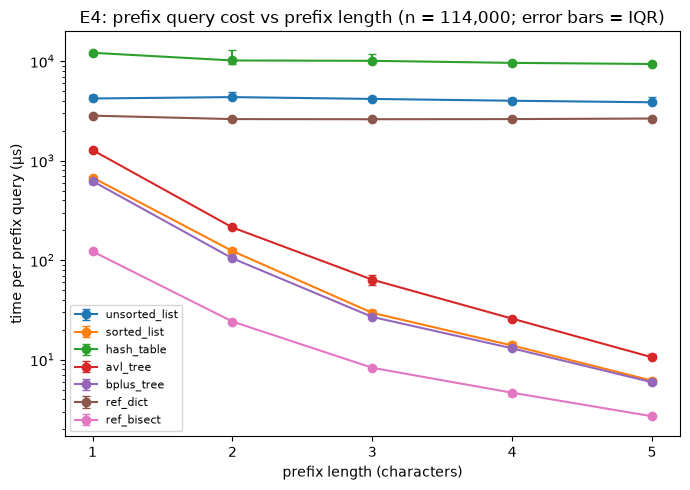

index_type,avl_tree,bplus_tree,hash_table,ref_bisect,ref_dict,sorted_list,unsorted_list
operation_param,,,,,,,
1.0,1278.4,623.0,12145.1,122.4,2835.5,676.9,4218.3
2.0,213.4,104.4,10169.4,24.2,2618.4,123.6,4355.8
3.0,63.7,26.9,10084.4,8.3,2609.7,29.6,4175.6
4.0,25.9,13.0,9615.3,4.7,2618.5,13.9,4004.3
5.0,10.6,5.9,9375.4,2.7,2653.5,6.2,3863.1


q1                                            \
index_type      avl_tree bplus_tree hash_table ref_bisect ref_dict   
operation_param                                                      
1.0               1235.5      587.1    11877.7      119.3   2832.0   
2.0                209.8      102.8     9362.1       23.5   2613.7   
3.0                 55.7       26.7     9652.3        8.1   2607.7   
4.0                 25.4       12.8     9222.1        4.3   2603.7   
5.0                 10.5        5.7     9151.1        2.6   2643.4   

                                                q3                        \
index_type      sorted_list unsorted_list avl_tree bplus_tree hash_table   
operation_param                                                            
1.0                   613.3        4193.4   1287.6      631.4    12334.0   
2.0                   117.4        4339.9    218.2      107.5    13029.5   
3.0                    28.4        4077.0     70.9       27.1    11712.8   
4.0                    13.8        3828.9     26.7       13.6     9792.8   
5.0                     6.1        3779.1     11.5        6.1     9896.4   

                                                               
index_type      ref_bisect ref_dict sorted_list unsorted_list  
operation_param                                                
1.0                  123.6   2853.9       693.6        4531.8  
2.0                   25.0   2664.9       133.2        4948.8  
3.0                    8.3   2622.9        31.9        4215.0  
4.0                    4.7   2621.3        15.0        4232.6  
5.0                    2.7   2656.4         6.6        4394.6

In [5]:
e4 = r[r['experiment'].str.startswith('E4')]
m4 = e4.groupby(['index_type', 'operation_param']).agg(
    us_per_op=('us_per_op', 'median'), q1=('us_per_op', q1), q3=('us_per_op', q3),
    cmp_per_op=('cmp_per_op', 'median')).reset_index()

fig, ax = plt.subplots(figsize=(7, 5))
for idx in INDEXES:
    g = m4[m4['index_type'] == idx]
    errbar(ax, g['operation_param'], g['us_per_op'], g['q1'], g['q3'], idx)
ax.set_yscale('log')
ax.set_xlabel('prefix length (characters)'); ax.set_ylabel('time per prefix query (µs)')
ax.set_title('E4: prefix query cost vs prefix length (n = 114,000; error bars = IQR)'); ax.legend(fontsize=8)
ax.set_xticks([1, 2, 3, 4, 5])
plt.tight_layout(); plt.savefig('figures/e4_prefix.png', dpi=150); plt.show()

display(m4.pivot(index='operation_param', columns='index_type', values='us_per_op').round(1))
display(m4.pivot(index='operation_param', columns='index_type', values=['q1', 'q3']).round(1))

## E5: insert order

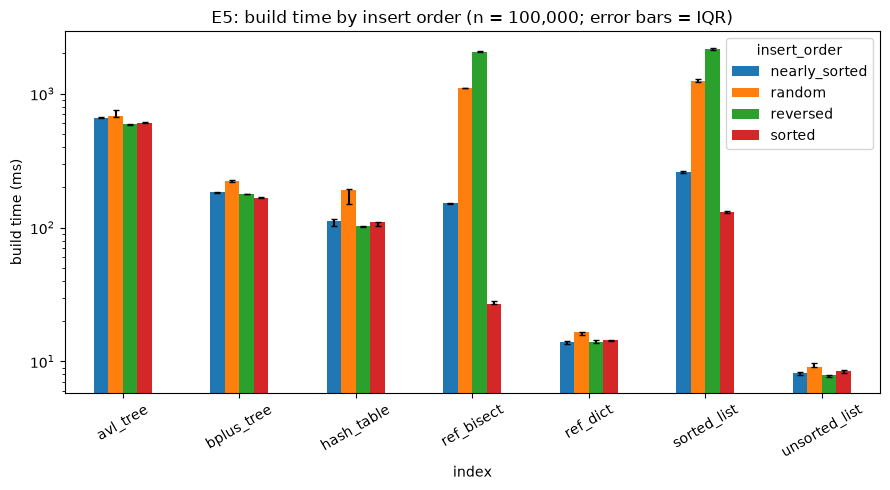

insert_order,nearly_sorted,random,reversed,sorted
index_type,,,,
avl_tree,664.0,678.7,590.0,609.7
bplus_tree,184.3,222.5,177.6,166.4
hash_table,111.7,189.5,102.0,109.5
ref_bisect,152.1,1098.5,2055.2,27.1
ref_dict,14.0,16.5,14.0,14.3
sorted_list,258.4,1235.9,2144.1,131.4
unsorted_list,8.2,9.1,7.9,8.5


q1                                    q3          \
insert_order  nearly_sorted  random reversed sorted nearly_sorted  random   
index_type                                                                  
avl_tree              663.1   673.9    589.0  605.7         665.4   756.4   
bplus_tree            181.9   217.9    177.0  166.0         185.1   227.1   
hash_table            102.2   150.7    101.7  102.5         115.3   193.3   
ref_bisect            150.1  1096.3   2045.2   26.9         152.6  1098.9   
ref_dict               13.6    15.6     13.7   14.2          14.2    16.6   
sorted_list           254.4  1222.1   2138.0  129.3         263.3  1283.2   
unsorted_list           7.9     9.0      7.7    8.2           8.4     9.8   

                               
insert_order  reversed sorted  
index_type                     
avl_tree         594.7  614.1  
bplus_tree       178.2  168.3  
hash_table       103.5  109.6  
ref_bisect      2076.7   28.3  
ref_dict          14.4   14.4  
sorted_list     2205.9  133.4  
unsorted_list      7.9    8.6

height  rotations  splits
index_type insert_order                            
avl_tree   nearly_sorted    20.0   120055.0     0.0
           random           20.0    70144.0     0.0
           reversed         17.0    99983.0     0.0
           sorted           17.0    99983.0     0.0
bplus_tree nearly_sorted     4.0        0.0  6135.0
           random            4.0        0.0  4829.0
           reversed          4.0        0.0  6661.0
           sorted            4.0        0.0  6635.0

insert_order,nearly_sorted,random,reversed,sorted
index_type,,,,
avl_tree,1.06,1.53,1.10,1.08
bplus_tree,1.85,1.95,1.77,1.92
hash_table,0.70,0.78,0.68,0.69
ref_bisect,0.54,0.53,0.52,0.55
ref_dict,0.24,0.25,0.27,0.25
sorted_list,1.71,1.80,1.50,2.20
unsorted_list,1713.50,1698.59,1699.38,1750.07


In [6]:
e5 = r[r['experiment'].str.startswith('E5')]
n5 = int(e5['n_keys'].max())
big = e5[e5['n_keys'] == n5]

g5 = big[big['operation'] == 'build'].groupby(['index_type', 'insert_order'])['total_ns']
build5 = g5.median().unstack() / 1e6
lo5 = g5.quantile(0.25).unstack() / 1e6
hi5 = g5.quantile(0.75).unstack() / 1e6
# pandas wants asymmetric error bars as an array of shape (columns, 2, rows)
err5 = np.stack([(build5 - lo5).T.values, (hi5 - build5).T.values], axis=1)
build5.plot(kind='bar', logy=True, yerr=err5, capsize=2, figsize=(9, 5))
plt.ylabel('build time (ms)'); plt.xlabel('index')
plt.title(f"E5: build time by insert order (n = {n5:,}; error bars = IQR)")
plt.xticks(rotation=30); plt.tight_layout(); plt.savefig('figures/e5_order.png', dpi=150); plt.show()
display(build5.round(1))
display(pd.concat({'q1': lo5, 'q3': hi5}, axis=1).round(1))

# tree shape and rebalancing work by order
shape = big[big['operation'] == 'build'].groupby(['index_type', 'insert_order'])[['height', 'rotations', 'splits']].median()
display(shape[shape.index.get_level_values(0).isin(['avl_tree', 'bplus_tree'])])

hit5 = big[big['operation'] == 'point_hit'].groupby(['index_type', 'insert_order'])['us_per_op'].median().unstack()
display(hit5.round(2))

## E6: B+ tree order

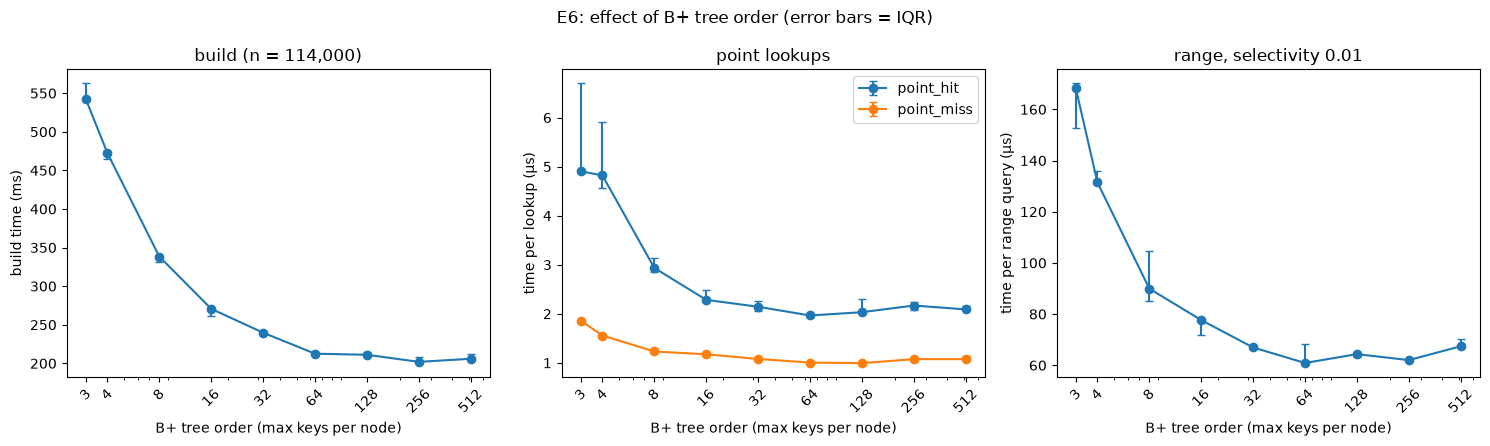

,order,build_ms,b_q1,b_q3,height,mem_MB
0,3,542.2,539.3,562.8,14.0,28.9
4,4,472.4,465.4,474.7,11.0,20.2
8,8,338.3,331.2,339.8,7.0,12.5
12,16,270.6,261.3,271.2,5.0,10.3
16,32,239.7,238.2,241.0,4.0,9.2
20,64,212.5,212.1,214.2,3.0,8.7
24,128,211.1,210.8,215.0,3.0,8.4
28,256,201.9,199.9,208.6,3.0,8.3
32,512,205.9,205.9,212.3,2.0,8.3


us                        us_q1                        us_q3  \
operation point_hit point_miss   range point_hit point_miss   range point_hit   
order                                                                           
3              4.90       1.86  168.18      4.88       1.81  152.53      6.70   
4              4.82       1.56  131.47      4.57       1.55  130.78      5.91   
8              2.94       1.23   89.94      2.85       1.21   85.09      3.14   
16             2.28       1.18   77.65      2.26       1.13   71.89      2.49   
32             2.14       1.08   66.94      2.07       1.08   66.18      2.26   
64             1.97       1.01   60.89      1.93       1.00   60.70      1.98   
128            2.03       0.99   64.34      2.02       0.99   63.13      2.29   
256            2.17       1.08   62.01      2.07       1.03   61.87      2.24   
512            2.09       1.08   67.42      2.07       1.05   67.15      2.16   

                              
operation point_miss   range  
order                         
3               1.86  170.16  
4               1.59  135.94  
8               1.26  104.68  
16              1.18   78.07  
32              1.09   67.41  
64              1.01   68.39  
128             1.02   65.00  
256             1.09   62.15  
512             1.15   70.26

In [7]:
e6 = r[r['experiment'].str.startswith('E6')].copy()
e6['order'] = e6['index_param'].str.extract(r'(\d+)').astype(int)

m6 = e6.groupby(['order', 'operation']).agg(
    us=('us_per_op', 'median'), us_q1=('us_per_op', q1), us_q3=('us_per_op', q3),
    build_ms=('total_ns', lambda x: x.median() / 1e6),
    b_q1=('total_ns', lambda x: x.quantile(0.25) / 1e6), b_q3=('total_ns', lambda x: x.quantile(0.75) / 1e6),
    mem=('memory_bytes', 'median'), height=('height', 'median')).reset_index()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
b = m6[m6['operation'] == 'build']
errbar(axes[0], b['order'], b['build_ms'], b['b_q1'], b['b_q3'], 'build')
axes[0].set_ylabel('build time (ms)'); axes[0].set_title('build (n = 114,000)')
for op in ['point_hit', 'point_miss']:
    g = m6[m6['operation'] == op]
    errbar(axes[1], g['order'], g['us'], g['us_q1'], g['us_q3'], op)
axes[1].set_ylabel('time per lookup (µs)'); axes[1].set_title('point lookups'); axes[1].legend()
g = m6[m6['operation'] == 'range']
errbar(axes[2], g['order'], g['us'], g['us_q1'], g['us_q3'], 'range')
axes[2].set_ylabel('time per range query (µs)'); axes[2].set_title('range, selectivity 0.01')
for ax in axes:
    ax.set_xscale('log'); ax.set_xlabel('B+ tree order (max keys per node)')
    ax.set_xticks(sorted(e6['order'].unique())); ax.set_xticklabels(sorted(e6['order'].unique()), rotation=45)
plt.suptitle('E6: effect of B+ tree order (error bars = IQR)'); plt.tight_layout(); plt.savefig('figures/e6_order.png', dpi=150); plt.show()

display(b[['order', 'build_ms', 'b_q1', 'b_q3', 'mem', 'height']].assign(mem_MB=lambda d: (d['mem'] / 1e6).round(1)).drop(columns='mem').round(1))
display(m6[m6['operation'] != 'build'].pivot(index='order', columns='operation', values=['us', 'us_q1', 'us_q3']).round(2))

## E7: many rows sharing a key

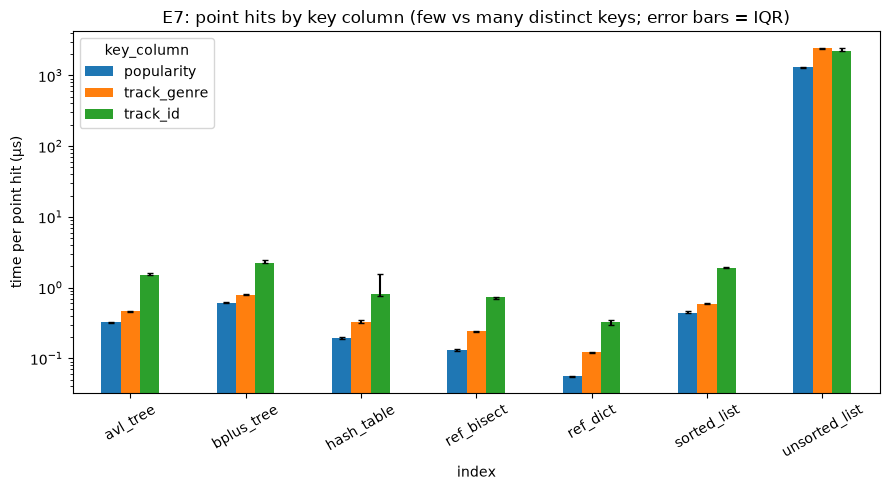

build (ms)


key_column,popularity,track_genre,track_id
index_type,,,
avl_tree,210.7,236.1,787.8
bplus_tree,87.0,83.1,272.3
hash_table,34.2,41.4,86.7
ref_bisect,17.3,21.9,932.2
ref_dict,9.8,13.4,21.4
sorted_list,58.0,58.2,1046.4
unsorted_list,9.3,11.8,11.2


point hit (µs)


key_column,popularity,track_genre,track_id
index_type,,,
avl_tree,0.33,0.47,1.51
bplus_tree,0.61,0.79,2.22
hash_table,0.20,0.33,0.81
ref_bisect,0.13,0.24,0.74
ref_dict,0.06,0.12,0.33
sorted_list,0.44,0.59,1.89
unsorted_list,1292.33,2452.49,2243.02


point hit IQR (µs)


q1                              q3                     
key_column    popularity track_genre track_id popularity track_genre track_id
index_type                                                                   
avl_tree            0.32        0.46     1.50       0.33        0.47     1.59
bplus_tree          0.61        0.78     2.19       0.63        0.80     2.46
hash_table          0.19        0.31     0.75       0.20        0.34     1.53
ref_bisect          0.13        0.24     0.69       0.13        0.24     0.74
ref_dict            0.06        0.12     0.30       0.06        0.12     0.35
sorted_list         0.44        0.59     1.87       0.47        0.61     1.94
unsorted_list    1277.52     2362.85  2210.89    1306.63     2453.04  2419.49

point miss (µs)


key_column,popularity,track_genre,track_id
index_type,,,
avl_tree,0.35,0.40,0.87
bplus_tree,0.56,0.69,1.20
hash_table,0.19,0.26,0.51
ref_bisect,0.10,0.17,0.16
ref_dict,0.06,0.09,0.22
sorted_list,0.36,0.53,0.92
unsorted_list,1524.55,2465.23,2377.80


popularity range (µs)


operation_param,0.01,0.05,0.10,0.25
index_type,,,,
avl_tree,4.8,20.3,40.6,118.7
bplus_tree,4.4,20.3,38.7,108.4
hash_table,10.8,26.3,45.5,118.6
ref_bisect,4.0,19.1,38.5,112.8
ref_dict,5.4,20.8,40.9,114.0
sorted_list,2.8,15.5,34.1,80.7
unsorted_list,1819.7,1866.7,1916.8,2122.2


In [8]:
e7 = r[r['experiment'].str.startswith('E7')]

build7 = e7[e7['operation'] == 'build'].groupby(['index_type', 'key_column'])['total_ns'].median().unstack() / 1e6
g7 = e7[e7['operation'] == 'point_hit'].groupby(['index_type', 'key_column'])['us_per_op']
hit7, lo7, hi7 = g7.median().unstack(), g7.quantile(0.25).unstack(), g7.quantile(0.75).unstack()
miss7 = e7[e7['operation'] == 'point_miss'].groupby(['index_type', 'key_column'])['us_per_op'].median().unstack()

err7 = np.stack([(hit7 - lo7).T.values, (hi7 - hit7).T.values], axis=1)
hit7.plot(kind='bar', logy=True, yerr=err7, capsize=2, figsize=(9, 5))
plt.ylabel('time per point hit (µs)'); plt.xlabel('index')
plt.title('E7: point hits by key column (few vs many distinct keys; error bars = IQR)')
plt.xticks(rotation=30); plt.tight_layout(); plt.savefig('figures/e7_duplicates.png', dpi=150); plt.show()

print("build (ms)"); display(build7.round(1))
print("point hit (µs)"); display(hit7.round(2))
print("point hit IQR (µs)"); display(pd.concat({'q1': lo7, 'q3': hi7}, axis=1).round(2))
print("point miss (µs)"); display(miss7.round(2))

# popularity range queries
rng7 = e7[e7['operation'] == 'range'].groupby(['index_type', 'operation_param'])['us_per_op'].median().unstack()
print("popularity range (µs)"); display(rng7.round(1))